# Mutual inductance in terms of self-inductance: $M = k\sqrt{L_1L_2}$
### SymPy derivation · numbers checked against closed forms · wireless charger, transformer, LCR bench

**In plain words.** A coil's self-inductance $L$ says how much magnetic flux its own current threads
through itself. Put a second coil nearby and some of that flux also threads the second coil; the
**mutual inductance** $M$ measures the shared part. The **coupling coefficient** $k$ is the fraction
shared, from 0 (coils far apart or at right angles) to 1 (every field line passes through both). The
rule tying them together is

$$M = k\sqrt{L_1 L_2},\qquad 0 \le k \le 1 .$$

Why can't $M$ be bigger? Because then you could pick two currents that store *negative* magnetic
energy, and energy $\int B^2/2\mu_0\,dV$ can't be negative. We show that in SymPy, check it with
the flux picture, compute $M$ three independent ways for real geometries (closed forms, Maxwell's
elliptic formula, Neumann's double integral), then use it to design a wireless charging pad and a
transformer and to measure $k$ on a bench with an LCR meter.

Module: `dgs/mutual_inductance.py`. Figures use the Okabe-Ito palette, curves differ by line style
too, and each figure has a printed text description.

In [1]:
import sys, pathlib, math
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, sympy as sp, matplotlib.pyplot as plt
from dgs import mutual_inductance as mi
sp.init_printing()
OI = ["#E69F00", "#56B4E9", "#009E73", "#D55E00", "#CC79A7", "#0072B2", "#000000"]
plt.rcParams["axes.prop_cycle"] = plt.cycler(color=OI)
MU0 = mi.MU0

## 1. The bound from energy (SymPy)

Two coils with currents $I_1, I_2$ store
$$W = \tfrac12 L_1 I_1^2 + \tfrac12 L_2 I_2^2 + M I_1 I_2 .$$
Set $x = I_1/I_2$. Then $W/I_2^2 = \tfrac12 L_1 x^2 + M x + \tfrac12 L_2$ is an upward parabola in $x$.
It stays $\ge 0$ for every $x$ exactly when it has no real roots, i.e. when its discriminant is
$\le 0$. SymPy finds the worst current ratio and the minimum energy.

In [2]:
d = mi.derive_energy_bound()
print("worst current ratio  x* = I1/I2 ="); display(d["x_star"])
print("minimum energy W_min ="); display(d["W_min"])
print("discriminant of W/I2^2 in x ="); display(d["discriminant"])
print("det of inductance matrix [[L1, M], [M, L2]] ="); display(d["det"])

worst current ratio  x* = I1/I2 =


minimum energy W_min =


discriminant of W/I2^2 in x =


det of inductance matrix [[L1, M], [M, L2]] =


$W_{\min} = \dfrac{(L_1L_2 - M^2)\,I_2^2}{2L_1} \ge 0$ forces $M^2 \le L_1L_2$. The same
statement in matrix language: the inductance matrix must be positive semidefinite, and for a
symmetric $2\times2$ matrix with positive diagonal that is just $\det = L_1L_2 - M^2 \ge 0$.
Defining $k = |M|/\sqrt{L_1L_2}$ turns the bound into $k \le 1$.

A numerical sanity check: push $M$ 1 % past the bound and drive the worst-case currents.

In [3]:
L1v, L2v = 2e-3, 5e-3
Mmax = math.sqrt(L1v*L2v)
for M in (0.99*Mmax, Mmax, 1.01*Mmax):
    x = -M/L1v
    print(f"M/sqrt(L1L2) = {M/Mmax:.2f}:  W(I1={x:+.3f} A, I2=1 A) = {mi.energy(L1v, L2v, M, x, 1.0)*1e6:+.3f} uJ,"
          f"  PSD: {mi.inductance_matrix_is_psd(L1v, L2v, M)}")

M/sqrt(L1L2) = 0.99:  W(I1=-1.565 A, I2=1 A) = +49.750 uJ,  PSD: True
M/sqrt(L1L2) = 1.00:  W(I1=-1.581 A, I2=1 A) = +0.000 uJ,  PSD: True
M/sqrt(L1L2) = 1.01:  W(I1=-1.597 A, I2=1 A) = -50.250 uJ,  PSD: False


## 2. The same bound from flux linkage (SymPy)

Coil 1 ($N_1$ turns, current $I_1$) makes flux $\Phi_1$ per turn; a fraction $k_1$ reaches coil 2.
Then $L_1 = N_1\Phi_1/I_1$ and $M = N_2 k_1\Phi_1/I_1$. From coil 2's side, $L_2 = N_2\Phi_2/I_2$ and
$M = N_1 k_2 \Phi_2/I_2$ (the two $M$'s are equal by Neumann's formula, which is symmetric in the two
loops). Multiply the two expressions for $M$:

In [4]:
N1, N2, I1, I2, P1, P2, k1, k2 = sp.symbols("N_1 N_2 I_1 I_2 Phi_1 Phi_2 k_1 k_2", positive=True)
L1, L2 = N1*P1/I1, N2*P2/I2
M_from_1, M_from_2 = N2*k1*P1/I1, N1*k2*P2/I2
print("M^2 / (L1 L2) ="); display(sp.simplify(M_from_1*M_from_2/(L1*L2)))

M^2 / (L1 L2) =


So $M^2 = k_1k_2\,L_1L_2$ and $k = \sqrt{k_1k_2}$, the geometric mean of the two leak-free
fractions. Each fraction is at most 1, so $k \le 1$ again, now with a picture: $k$ is "how much of the
flux is shared".

### Long coaxial solenoids
Outer coil ($N_2$, area $A_2$) makes a uniform $B = \mu_0N_2I_2/\ell$ inside; the inner coil
(area $A_1 \le A_2$) catches $BA_1$ per turn.

In [5]:
mu0, l, A1, A2 = sp.symbols("mu_0 ell A_1 A_2", positive=True)
Ls1, Ls2 = mu0*N1**2*A1/l, mu0*N2**2*A2/l
Ms = N1*(mu0*N2/l)*A1                         # N1 * flux per turn per unit I2
ks = sp.simplify(Ms/sp.sqrt(Ls1*Ls2))
print("k ="); display(ks)
print("k when A1 = A2:", ks.subs(A1, A2))

k =

k when A1 = A2: 1


## 3. Series aiding and opposing: a measurement recipe (SymPy)

Wire the coils in series so the same current flows in both. Aiding: $I_1 = I_2 = I$; opposing (one
coil flipped): $I_2 = -I$. Read the effective inductance off $W = \tfrac12 L_\text{eq} I^2$.

In [6]:
Ls1_, Ls2_ = sp.symbols("L_1 L_2", positive=True); M_, I = sp.symbols("M I", real=True)
W = lambda a, b: sp.Rational(1, 2)*Ls1_*a**2 + sp.Rational(1, 2)*Ls2_*b**2 + M_*a*b
L_aid = sp.simplify(2*W(I, I)/I**2); L_opp = sp.simplify(2*W(I, -I)/I**2)
print("L_aid ="); display(L_aid); print("L_opp ="); display(L_opp)
print("(L_aid - L_opp)/4 ="); display(sp.simplify((L_aid - L_opp)/4))

L_aid =


L_opp =


(L_aid - L_opp)/4 =


So two LCR readings give $M = (L_\text{aid} - L_\text{opp})/4$, and two more (each coil alone)
give $k$.

## 4. Transformer: T-equivalent and the ideal limit (SymPy)

With a shared ground the two-port obeys $V_1 = j\omega(L_1I_1 + MI_2)$,
$V_2 = j\omega(MI_1 + L_2I_2)$. A T network with series arms $L_1 - M$, $L_2 - M$ and shunt arm $M$
has the same impedance matrix. Loading port 2 with $Z_L$ ($V_2 = -Z_LI_2$) gives the input impedance
and voltage ratio.

T-network matrix == [[L1, M], [M, L2]]: True
Z_in =


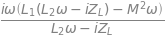

V2/V1 at k = 1 (M = sqrt(L1 L2)):


In [7]:
w, ZL = sp.symbols("omega Z_L")
a_, b_, c_ = Ls1_ - M_, Ls2_ - M_, M_
Z_T = sp.Matrix([[a_ + c_, c_], [c_, b_ + c_]])          # T network, open-circuit impedance matrix / (j w)
print("T-network matrix == [[L1, M], [M, L2]]:", sp.simplify(Z_T - sp.Matrix([[Ls1_, M_], [M_, Ls2_]])) == sp.zeros(2))
i1, i2 = sp.symbols("i_1 i_2")
sol = sp.solve([sp.I*w*(M_*i1 + Ls2_*i2) + ZL*i2], i2, dict=True)[0]
Zin = sp.simplify(sp.I*w*(Ls1_*i1 + M_*sol[i2])/i1)
ratio = sp.simplify(-ZL*sol[i2]/(Zin*i1))
print("Z_in ="); display(Zin)
print("V2/V1 at k = 1 (M = sqrt(L1 L2)):"); display(sp.simplify(ratio.subs(M_, sp.sqrt(Ls1_*Ls2_))))

At $k = 1$ the voltage ratio is exactly $\sqrt{L_2/L_1} = N_2/N_1$ for **any** load: the turns
ratio. (Since $L \propto N^2$ on the same core, $\sqrt{L_2/L_1} = N_2/N_1$.) If in addition
$L_1, L_2 \to \infty$ at fixed ratio, $Z_\text{in} \to Z_L\,L_1/L_2 = Z_L/n^2$: the ideal
transformer. Real transformers miss on both counts: $k < 1$ leaves leakage inductance $(1-k)L$ in
series, and finite $L_1$ draws a magnetizing current.

## 5. Numbers against closed forms

### 5a. Nested solenoids
100 and 200 turns on 10 cm, radii 5 mm (inner) and 5 or 10 mm (outer).

In [8]:
for r2 in (5e-3, 10e-3):
    r = mi.nested_solenoids(100, math.pi*(5e-3)**2, 200, math.pi*r2**2, 0.1)
    print(f"outer radius {r2*1e3:.0f} mm: L1 = {r['L1']*1e6:.2f} uH, L2 = {r['L2']*1e6:.2f} uH, "
          f"M = {r['M']*1e6:.2f} uH, k = {r['k']:.4f}  (closed form sqrt(A1/A2) = {math.sqrt((5e-3)**2/r2**2):.4f})")

outer radius 5 mm: L1 = 9.87 uH, L2 = 39.48 uH, M = 19.74 uH, k = 1.0000  (closed form sqrt(A1/A2) = 1.0000)
outer radius 10 mm: L1 = 9.87 uH, L2 = 157.91 uH, M = 19.74 uH, k = 0.5000  (closed form sqrt(A1/A2) = 0.5000)


### 5b. Two coaxial loops, three ways

* **Maxwell (1873), elliptic integrals:** $M = \mu_0\sqrt{ab}\,[(2/m - m)K(m) - (2/m)E(m)]$,
  $m^2 = 4ab/((a+b)^2 + d^2)$. $K, E$ via the arithmetic-geometric mean.
* **Neumann, reduced to one angle:** $M = \tfrac{\mu_0ab}{2}\int_0^{2\pi}\cos\varphi\,
  /\sqrt{a^2+b^2+d^2-2ab\cos\varphi}\,d\varphi$.
* **Neumann, brute force:** $M = \tfrac{\mu_0}{4\pi}\oint\oint d\mathbf l_1\cdot d\mathbf l_2/|\mathbf r_1-\mathbf r_2|$
  summed over two 600-segment polygons. This one doesn't know the loops are circles or coaxial.

Far apart the loops act like magnetic dipoles: $M \to \mu_0\pi a^2b^2/2d^3$.

In [9]:
a, b = 0.02, 0.03
print(f"{'d (mm)':>7} {'Maxwell (nH)':>13} {'Neumann 1-D':>13} {'Neumann 2-D':>13} {'rel err 2-D':>11}")
for dd in (0.0, 0.005, 0.01, 0.03, 0.1):
    Mx = mi.coaxial_loops_mutual(a, b, dd)
    n1 = mi.neumann_coaxial(a, b, dd)
    n2 = mi.neumann_polyline(mi.circle_points(a, n=600), mi.circle_points(b, (0, 0, dd), n=600))
    print(f"{dd*1e3:7.1f} {Mx*1e9:13.6f} {n1*1e9:13.6f} {n2*1e9:13.6f} {abs(n2/Mx-1):11.2e}")

 d (mm)  Maxwell (nH)   Neumann 1-D   Neumann 2-D rel err 2-D
    0.0     32.539126     32.539126     32.539274    4.57e-06
    5.0     29.594939     29.594939     29.595003    2.16e-06
   10.0     23.693002     23.693002     23.692945    2.41e-06


   30.0      8.089103      8.089103      8.088970    1.65e-05


  100.0      0.594732      0.594732      0.594713    3.21e-05


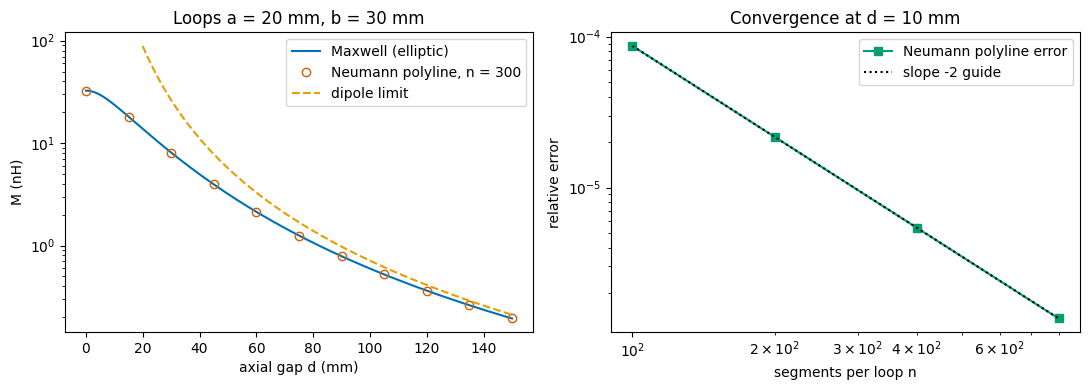

Text description: left, mutual inductance of two coaxial loops (20 and 30 mm radius) on a log scale against their gap. The solid blue Maxwell curve falls from 32.5 nH at d = 0 to 0.19 nH at 150 mm; the open vermillion circles from the brute-force Neumann sum sit on it; the dashed orange dipole law overshoots at small gaps and merges with the curve once d is several loop radii. Right, the Neumann polyline error against segment count on log-log axes: a straight green line of fitted slope -2.00, parallel to the dotted slope -2 guide, i.e. error proportional to 1/n^2.


In [10]:
d = np.linspace(0.0, 0.15, 151)
Mx = np.array([mi.coaxial_loops_mutual(a, b, x) for x in d])
dip = MU0*np.pi*a**2*b**2/(2*np.maximum(d, 1e-9)**3)
dpts = np.linspace(0.0, 0.15, 11)
npts = [mi.neumann_polyline(mi.circle_points(a, n=300), mi.circle_points(b, (0, 0, x), n=300)) for x in dpts]
nconv = [100, 200, 400, 800]
exact = mi.coaxial_loops_mutual(a, b, 0.01)
errs = [abs(mi.neumann_polyline(mi.circle_points(a, n=n), mi.circle_points(b, (0, 0, 0.01), n=n))/exact - 1) for n in nconv]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].semilogy(d*1e3, Mx*1e9, "-", color=OI[5], label="Maxwell (elliptic)")
ax[0].semilogy(dpts*1e3, np.array(npts)*1e9, "o", color=OI[3], mfc="none", label="Neumann polyline, n = 300")
ax[0].semilogy(d[20:]*1e3, dip[20:]*1e9, "--", color=OI[0], label="dipole limit")
ax[0].set_xlabel("axial gap d (mm)"); ax[0].set_ylabel("M (nH)"); ax[0].legend(); ax[0].set_title("Loops a = 20 mm, b = 30 mm")
ax[1].loglog(nconv, errs, "s-", color=OI[2], label="Neumann polyline error")
ax[1].loglog(nconv, errs[0]*(nconv[0]/np.array(nconv))**2, ":", color=OI[6], label="slope -2 guide")
ax[1].set_xlabel("segments per loop n"); ax[1].set_ylabel("relative error"); ax[1].legend(); ax[1].set_title("Convergence at d = 10 mm")
plt.tight_layout(); plt.show()
slope = np.polyfit(np.log(nconv), np.log(errs), 1)[0]
print("Text description: left, mutual inductance of two coaxial loops (20 and 30 mm radius) on a log scale "
      f"against their gap. The solid blue Maxwell curve falls from {Mx[0]*1e9:.1f} nH at d = 0 to {Mx[-1]*1e9:.2f} nH "
      "at 150 mm; the open vermillion circles from the brute-force Neumann sum sit on it; the dashed orange dipole "
      "law overshoots at small gaps and merges with the curve once d is several loop radii. Right, the "
      f"Neumann polyline error against segment count on log-log axes: a straight green line of fitted slope {slope:.2f}, "
      "parallel to the dotted slope -2 guide, i.e. error proportional to 1/n^2.")

## 6. Design example: wireless charging coil pair

A phone charging pad and the phone each carry a flat spiral: here 10 turns of 0.9 mm litz from
10.5 mm to 21.5 mm radius (a Qi-like size; dimensions chosen for illustration, not from the Qi
spec). Model each turn as a circular filament: the coil's $L$ is every turn's self-inductance plus
every pair's mutual, and the coil-to-coil $M$ is the sum over all turn pairs. No ferrite here: real
pads put a ferrite sheet behind each coil, which raises $L$ (often roughly doubling it) and $k$, so
these air-core numbers are a lower bound.

In [11]:
r = mi.spiral_radii(0.0105, 0.0215, 10)
L = mi.spiral_self_inductance(r, 0.45e-3)
print(f"air-core coil inductance L = {L*1e6:.2f} uH")
gaps = np.linspace(0.002, 0.03, 29)
k_gap = np.array([mi.spiral_mutual(r, r, g)/L for g in gaps])
offs = np.linspace(0, 0.03, 13)
k_off = np.array([mi.spiral_mutual_offset(r, r, 0.005, x, n=120)/L for x in offs])
Q = 100
eta_gap = np.array([mi.link_efficiency_max(k, Q, Q) for k in k_gap])
for g in (0.003, 0.005, 0.01):
    k = mi.spiral_mutual(r, r, g)/L
    print(f"gap {g*1e3:4.1f} mm: M = {k*L*1e6:.2f} uH, k = {k:.3f}, best link efficiency (Q = {Q}) = {mi.link_efficiency_max(k, Q, Q):.3f}")

air-core coil inductance L = 3.69 uH


gap  3.0 mm: M = 2.63 uH, k = 0.715, best link efficiency (Q = 100) = 0.972
gap  5.0 mm: M = 2.11 uH, k = 0.573, best link efficiency (Q = 100) = 0.966
gap 10.0 mm: M = 1.28 uH, k = 0.347, best link efficiency (Q = 100) = 0.944


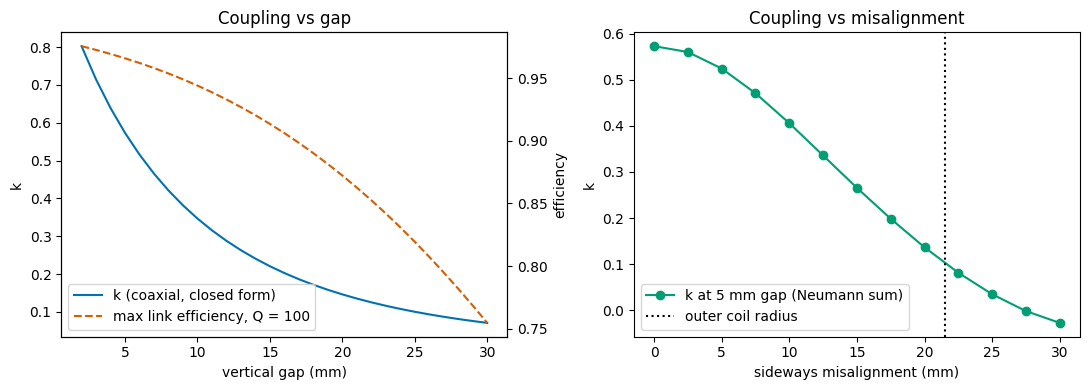

Text description: left, the solid blue curve is k between two identical 10-turn air-core spirals falling from 0.80 at a 2 mm gap to 0.071 at 30 mm; the dashed vermillion curve (right axis) is the best possible link efficiency with coil Q = 100, which stays above 90 % until the gap passes about 17 mm (k = 0.19) and is 0.75 at 30 mm. Right, the green markers show k at a 5 mm gap against sideways offset: 0.57 when centred, 0.41 at 10 mm, 0.136 at 20 mm near the dotted line at one outer radius, and -0.028 at 30 mm, i.e. slightly negative: there the return field of coil 1 threads coil 2 the opposite way.


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(gaps*1e3, k_gap, "-", color=OI[5], label="k (coaxial, closed form)")
ax[0].set_xlabel("vertical gap (mm)"); ax[0].set_ylabel("k")
ax2 = ax[0].twinx(); ax2.plot(gaps*1e3, eta_gap, "--", color=OI[3], label="max link efficiency, Q = 100"); ax2.set_ylabel("efficiency")
h1, l1 = ax[0].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels(); ax[0].legend(h1+h2, l1+l2, loc="lower left")
ax[0].set_title("Coupling vs gap")
ax[1].plot(offs*1e3, k_off, "o-", color=OI[2], label="k at 5 mm gap (Neumann sum)")
ax[1].axvline(r[-1]*1e3, ls=":", color=OI[6], label="outer coil radius")
ax[1].set_xlabel("sideways misalignment (mm)"); ax[1].set_ylabel("k"); ax[1].legend(); ax[1].set_title("Coupling vs misalignment")
plt.tight_layout(); plt.show()
print("Text description: left, the solid blue curve is k between two identical 10-turn air-core spirals "
      f"falling from {k_gap[0]:.2f} at a 2 mm gap to {k_gap[-1]:.3f} at 30 mm; the dashed vermillion curve (right axis) is the "
      f"best possible link efficiency with coil Q = 100, which stays above 90 % until the gap passes about "
      f"{gaps[np.argmax(eta_gap < 0.9)]*1e3:.0f} mm (k = {k_gap[np.argmax(eta_gap < 0.9)]:.2f}) and is {eta_gap[-1]:.2f} at 30 mm. "
      f"Right, the green markers show k at a 5 mm gap against sideways offset: {k_off[0]:.2f} when centred, "
      f"{k_off[np.argmin(abs(offs-0.01))]:.2f} at 10 mm, {k_off[np.argmin(abs(offs-0.02))]:.3f} at 20 mm near the dotted line "
      f"at one outer radius, and {k_off[-1]:+.3f} at 30 mm"
      + (", i.e. slightly negative: there the return field of coil 1 threads coil 2 the opposite way." if k_off.min() < 0 else "."))

Design reading: $k$ is set by geometry alone (gap and misalignment relative to coil radius), while
efficiency needs $k^2Q_1Q_2 \gg 1$. That is why chargers use resonant capacitors, high-Q litz coils,
ferrite to boost $k$, and magnets or alignment guides: once the offset reaches about one coil radius,
$k$ collapses.

## 7. Design example: 120 V to 12 V mains transformer

Turns ratio $n = 1/10$ means $L_2/L_1 = 1/100$. Choose $L_1 = 2$ H (magnetizing current
$120/(2\pi\cdot60\cdot2) \approx 0.16$ A, a few percent of full load on a large unit) and look at
what $k < 1$ does to regulation into loads of different size.

k = 0.99: M = 0.1980 H, T arms: L1-M = 1802.00 mH, L2-M = -178.00 mH, shunt M = 0.1980 H; leakage (1-k)L1 = 20.0 mH
k = 0.999: M = 0.1998 H, T arms: L1-M = 1800.20 mH, L2-M = -179.80 mH, shunt M = 0.1998 H; leakage (1-k)L1 = 2.0 mH
magnetizing current at 120 V: 0.159 A


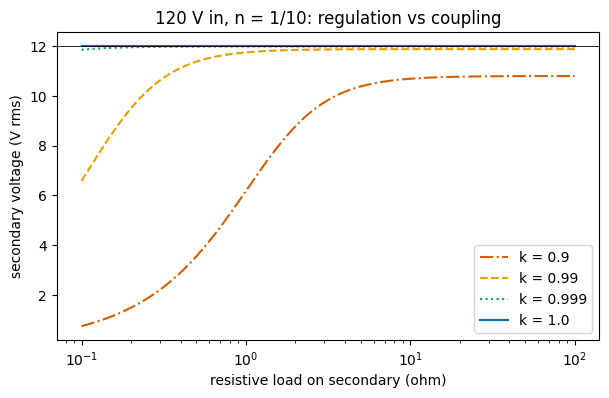

Text description: secondary voltage against load resistance (log axis) for four couplings. The solid blue k = 1 line is flat at exactly 12 V for every load. With k = 0.999 (dotted green) the voltage is 11.99 V at 100 ohm and 11.99 V at 1 ohm; k = 0.99 (dashed orange) gives 11.75 V at 1 ohm; k = 0.9 (dash-dot vermillion) sags to 6.18 V at 1 ohm and already reads 10.80 V lightly loaded. Unloaded, V2/V1 = M/L1 = k n, so the open-circuit voltage is k x 12 V; leakage inductance in series with the load adds the sag under heavy load. The thin black line marks 12 V.


In [13]:
L1t, L2t, f = 2.0, 0.02, 60.0
om = 2*np.pi*f
for k in (0.99, 0.999):
    Mt = mi.mutual_inductance(L1t, L2t, k)
    a_t, b_t, c_t = mi.t_equivalent(L1t, L2t, Mt)
    lk = mi.leakage_and_magnetizing(L1t, L2t, k)
    print(f"k = {k}: M = {Mt:.4f} H, T arms: L1-M = {a_t*1e3:.2f} mH, L2-M = {b_t*1e3:+.2f} mH, shunt M = {c_t:.4f} H; "
          f"leakage (1-k)L1 = {lk['leak1']*1e3:.1f} mH")
print(f"magnetizing current at 120 V: {120/(om*L1t):.3f} A")
loads = np.logspace(-1, 2, 200)
fig, ax = plt.subplots(figsize=(7, 4))
for k, ls, c in ((0.9, "-.", OI[3]), (0.99, "--", OI[0]), (0.999, ":", OI[2]), (1.0, "-", OI[5])):
    Mt = mi.mutual_inductance(L1t, L2t, k)
    ax.semilogx(loads, [120*abs(mi.voltage_ratio(L1t, L2t, Mt, R, om)) for R in loads], ls, color=c, label=f"k = {k}")
ax.axhline(12, color=OI[6], lw=0.6)
ax.set_xlabel("resistive load on secondary (ohm)"); ax.set_ylabel("secondary voltage (V rms)")
ax.set_title("120 V in, n = 1/10: regulation vs coupling"); ax.legend(); plt.show()
v = lambda k, R: 120*abs(mi.voltage_ratio(L1t, L2t, mi.mutual_inductance(L1t, L2t, k), R, om))
print("Text description: secondary voltage against load resistance (log axis) for four couplings. The solid blue "
      "k = 1 line is flat at exactly 12 V for every load. With k = 0.999 (dotted green) the voltage is "
      f"{v(0.999, 100):.2f} V at 100 ohm and {v(0.999, 1):.2f} V at 1 ohm; k = 0.99 (dashed orange) gives {v(0.99, 1):.2f} V at 1 ohm; "
      f"k = 0.9 (dash-dot vermillion) sags to {v(0.9, 1):.2f} V at 1 ohm and already reads {v(0.9, 100):.2f} V lightly loaded. "
      "Unloaded, V2/V1 = M/L1 = k n, so the open-circuit voltage is k x 12 V; leakage inductance in series with the "
      "load adds the sag under heavy load. The thin black line marks 12 V.")

## 8. Measuring $k$ on the bench with an LCR meter

**Recipe A (series aiding / opposing)**, coils fixed in place:
1. Measure $L_1$ alone (coil 2 open), then $L_2$ alone.
2. Connect the coils in series; measure $L_a$.
3. Swap the leads of one coil only; measure $L_b$. The larger reading is $L_\text{aid}$.
4. $M = (L_\text{aid} - L_\text{opp})/4$, $k = M/\sqrt{L_1L_2}$. The sign tells you where the dots are.

**Recipe B (open / short)**, needs only one winding's terminals:
1. Measure $L_\text{open}$ at coil 1 with coil 2 open.
2. Short coil 2 with a thick, short jumper; measure $L_\text{short} = L_1(1-k^2)$.
3. $k = \sqrt{1 - L_\text{short}/L_\text{open}}$.

Practical notes: use a test frequency where the coils are well below self-resonance (often 1 to
100 kHz), keep leads short and run the meter's open/short compensation, and in recipe B the jumper's
resistance must be small compared with $\omega L_2$ or $L_\text{short}$ reads high.

Which recipe is better? Simulate a meter with 0.5 % (1 sigma) independent error per reading on
coils of $L_1 = 10$ µH, $L_2 = 22$ µH and see how well each recovers $k$.

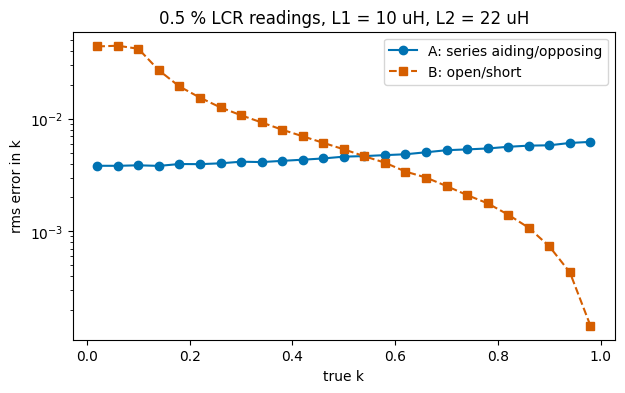

Text description: rms error of the recovered k (log axis) against true k for the two recipes. Recipe A (blue circles, solid) stays near 0.0038 to 0.0062 across the range, growing slowly with k. Recipe B (vermillion squares, dashed) is poor for weak coupling (0.044 at k = 0.02, because 1 - L_short/L_open is the small difference of two nearly equal readings) and becomes better than A from about k = 0.54 upward (0.0001 at k = 0.98).


In [14]:
rng = np.random.default_rng(1)
L1b, L2b, sig, trials = 10e-6, 22e-6, 0.005, 4000
noisy = lambda x: x*(1 + sig*rng.standard_normal(trials))
ks = np.linspace(0.02, 0.98, 25)
sdA, sdB = [], []
for k in ks:
    M = mi.mutual_inductance(L1b, L2b, k)
    l1, l2 = noisy(L1b), noisy(L2b)
    la, lo = noisy(L1b + L2b + 2*M), noisy(L1b + L2b - 2*M)
    kA = (la - lo)/4/np.sqrt(l1*l2)
    lop, lsh = noisy(L1b), noisy(L1b*(1 - k**2))
    kB = np.sqrt(np.clip(1 - lsh/lop, 0, None))
    sdA.append(np.std(kA - k)); sdB.append(np.sqrt(np.mean((kB - k)**2)))
sdA, sdB = np.array(sdA), np.array(sdB)
fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(ks, sdA, "o-", color=OI[5], label="A: series aiding/opposing")
ax.semilogy(ks, sdB, "s--", color=OI[3], label="B: open/short")
ax.set_xlabel("true k"); ax.set_ylabel("rms error in k"); ax.legend(); ax.set_title("0.5 % LCR readings, L1 = 10 uH, L2 = 22 uH")
plt.show()
cross = ks[np.argmax(sdB < sdA)]
print("Text description: rms error of the recovered k (log axis) against true k for the two recipes. "
      f"Recipe A (blue circles, solid) stays near {sdA.min():.4f} to {sdA.max():.4f} across the range, growing slowly with k. "
      f"Recipe B (vermillion squares, dashed) is poor for weak coupling ({sdB[0]:.3f} at k = {ks[0]:.2f}, because "
      "1 - L_short/L_open is the small difference of two nearly equal readings) and becomes better than A from about "
      f"k = {cross:.2f} upward ({sdB[-1]:.4f} at k = {ks[-1]:.2f}).")

Rule of thumb from the simulation: **loosely coupled coils (wireless links, sensors): series
aiding/opposing. Tightly coupled (transformers): open/short**, which also gives the leakage inductance
$L_\text{short}$ directly, the number a power-supply designer actually needs.

## How this connects

* **Faraday and Neumann.** Griffiths ch. 7 derives Neumann's formula and $M_{12} = M_{21}$; see
  `griffiths/electrodynamics.py` for the Faraday's-law material in this repo.
* **Circuits.** `dgs.ac_circuits` (phasors) and `dgs.spice` (MNA) are where the T-equivalent drops in
  as three ordinary inductors.
* **Measurement.** `dgs.error_propagation` does the same Monte-Carlo uncertainty propagation as
  section 8 in general form.
* **Tests:** `PYTHONPATH=. python -m pytest tests/test_mutual_inductance.py -q`.

**References** (IEEE style, written from memory; check details before citing):

[1] D. J. Griffiths, *Introduction to Electrodynamics*, 4th ed. Cambridge, U.K.: Cambridge Univ. Press, 2017, ch. 7.
[2] J. C. Maxwell, *A Treatise on Electricity and Magnetism*, vol. 2. Oxford, U.K.: Clarendon Press, 1873.
[3] F. W. Grover, *Inductance Calculations*. New York, NY, USA: Van Nostrand, 1946.
[4] A. Kurs *et al.*, "Wireless power transfer via strongly coupled magnetic resonances," *Science*, vol. 317, no. 5834, pp. 83-86, 2007.